# Lab 1: Базові алгоритми класифікації у Scikit-learn

## Мета роботи
Ознайомитися з базовим workflow задачі класифікації: від вибору та аналізу даних до навчання, налаштування, порівняння та оцінювання моделей машинного навчання з використанням бібліотеки Scikit-learn.

## Датасет
Phishing URL / Websites dataset з Kaggle - файл `final_dataset.csv` (kagglehub-ідентифікатор `elifzelik/phishing-url-features-dataset`, саме його завантажує код нижче). Кожен рядок - один URL, описаний лексичними ознаками URL та DNS/WHOIS-ознаками домену. Ціль `label`: `0` - легітимний сайт, `1` - фішинговий.

## Завдання
1. Завантаження та первинний аналіз даних
2. Попередня обробка даних
3. Візуалізація та дослідження даних (EDA)
4. Підготовка даних до навчання
5. Навчання моделей: kNN, Decision Tree, SVM, Random Forest, AdaBoost
6. Підбір гіперпараметрів
7. Порівняння та оцінювання моделей

## 1) Завантаження та первинний аналіз даних
Завантажити датасет; вивести назви колонок та розмір датасета; визначити ознаки (features) та цільову змінну (target); перевірити типи даних та розподіл об'єктів за класами.

In [1]:
import os
import time
import warnings
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

print("Setup!")

c:\Users\oleks\OneDrive\Desktop\Інтелектуальний аналіз даних\Lab1\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Setup!


In [2]:
# Шукаємо файл локально (поруч із ноутбуком або в папці data/).
# Якщо його немає - завантажуємо за допомогою kagglehub.
CSV_NAME = "final_dataset.csv"
candidates = [CSV_NAME, os.path.join("data", CSV_NAME)]
csv_path = next((p for p in candidates if os.path.exists(p)), None)

if csv_path is None:
    path = kagglehub.dataset_download("elifzelik/phishing-url-features-dataset")
    print(f"Path to dataset files: {path}")
    print(f"Files in dataset directory: {os.listdir(path)}")
    csv_path = os.path.join(path, CSV_NAME)

print(f"Using file: {csv_path}")
df = pd.read_csv(csv_path)

print(df.head())
print()
df.info()

Path to dataset files: C:\Users\oleks\.cache\kagglehub\datasets\elifzelik\phishing-url-features-dataset\versions\2
Files in dataset directory: ['dataset_info.txt', 'feature_description.csv', 'final_dataset.csv', 'README.md']
Using file: C:\Users\oleks\.cache\kagglehub\datasets\elifzelik\phishing-url-features-dataset\versions\2\final_dataset.csv
                                                 url  label  url_length  \
0  http://%20%25**)(**@fbrasil.com/old/lqjj0ukuvg...      1          57   
1  https://*f003.backblazeb2.com*/file/pesosi/hom...      1          52   
2  http://0-docusign-secured-843439-1-srs09.repli...      1          52   
3                          http://0-olx.1850943.xyz/      1          25   
4                http://0.0.0.0forum.cryptonight.net      1          35   

   domain_length  hostname_length  path_length  first_dir_length  tld_length  \
0              7               24           26                 3           3   
1              4               22         

In [3]:
print("=" * 70)
print("DATASET SIZE")
print("=" * 70)

print(f"Number of objects (rows): {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")
print(f"Dataset shape: {df.shape}")


print("\n" + "=" * 70)
print("COLUMN NAMES")
print("=" * 70)

for i, column in enumerate(df.columns, start=1):
    print(f"{i:2}. {column}")


target = "label"

X = df.drop(columns=[target])
y = df[target]

print("\n" + "=" * 70)
print("FEATURES AND TARGET")
print("=" * 70)

print(f"Target variable: {target}")
print(f"Number of features: {X.shape[1]}")


print("\n" + "=" * 70)
print("DATA TYPES")
print("=" * 70)

print("Number of columns by data type:")
print(df.dtypes.astype(str).value_counts())


print("\n" + "=" * 70)
print("MISSING VALUES")
print("=" * 70)

print(f"Total missing values: {df.isnull().sum().sum()}")


print("\n" + "=" * 70)
print("CLASS DISTRIBUTION")
print("=" * 70)

class_names = {0: "Legitimate", 1: "Phishing"}
class_counts = y.value_counts().sort_index()
class_percent = y.value_counts(normalize=True).sort_index() * 100

for class_value, count in class_counts.items():
    print(
        f"Class {class_value} ({class_names.get(class_value, 'Unknown')}): "
        f"{count} objects ({class_percent[class_value]:.2f}%)"
    )

DATASET SIZE
Number of objects (rows): 579920
Number of columns: 76
Dataset shape: (579920, 76)

COLUMN NAMES
 1. url
 2. label
 3. url_length
 4. domain_length
 5. hostname_length
 6. path_length
 7. first_dir_length
 8. tld_length
 9. tld_length_domain
10. url_depth
11. query_length
12. path_segments_count
13. num_digits
14. num_letters
15. num_special_chars
16. num_dots
17. num_hyphens
18. num_at
19. num_percent
20. num_equals
21. num_question
22. num_ampersand
23. num_hash
24. num_underscore
25. num_special
26. num_slash
27. num_params
28. entropy_url
29. entropy_hostname
30. entropy_domain
31. entropy_path
32. query_entropy
33. ratio_digits
34. ratio_letters
35. ratio_special_chars
36. uppercase_ratio
37. lowercase_ratio
38. is_ip_address
39. starts_with_ip
40. is_suspicious_tld
41. uses_https
42. has_www
43. unusual_double_slash
44. multiple_http
45. contains_port_number
46. path_has_encoded_chars
47. query_has_base64
48. contains_login
49. contains_secure
50. contains_verify
51.

### Перевірка: чи підходить датасет для задачі класифікації

In [4]:
n_classes = y.nunique()
imbalance = class_counts.max() / class_counts.min()
n_numeric = X.select_dtypes(include="number").shape[1]

print(f"Target '{target}' is discrete, unique values: {sorted(y.unique())}  ->  {n_classes} classes")
print(f"Task type: {'binary' if n_classes == 2 else 'multiclass'} classification")
print(f"Class imbalance ratio (majority / minority): {imbalance:.2f}")
print(f"Samples per feature: {len(df) / X.shape[1]:.0f}")
print(f"Numeric features: {n_numeric} of {X.shape[1]} (the rest is the raw 'url' text)")
print(f"Missing values: {df.isnull().sum().sum()}")

Target 'label' is discrete, unique values: [np.int64(0), np.int64(1)]  ->  2 classes
Task type: binary classification
Class imbalance ratio (majority / minority): 1.41
Samples per feature: 7732
Numeric features: 74 of 75 (the rest is the raw 'url' text)
Missing values: 0


**Висновок щодо придатності датасета.** Цільова змінна `label` - дискретна з двома значеннями (0 - легітимний, 1 - фішинговий), тобто це задача **бінарної класифікації**. Класи майже збалансовані (≈58,5 % / 41,5 %, співвідношення ≈1,41), об'єктів дуже багато (≈580 тис.), пропущених значень немає, майже всі ознаки числові. Через невелику нерівність класів, окрім accuracy далі використовуємо precision / recall / F1 для класу «Phishing» та ROC-AUC.

## 2) Попередня обробка даних
Перевірити наявність пропущених значень; за необхідності заповнити або видалити пропуски; якщо датасет містить категоріальні ознаки, виконати їх кодування; коротко пояснити прийняті рішення щодо попередньої обробки даних.

In [ ]:
print("=" * 70)
print("DATA PREPROCESSING")
print("=" * 70)

target = "label"

# ------------------------------------------------------------
# 1. Пропущені значення
# ------------------------------------------------------------
missing = df.isnull().sum()
missing_columns = missing[missing > 0]

print("\nMissing values:")
if len(missing_columns) == 0:
    print("No missing values found.")
else:
    print(missing_columns)

if df.isnull().sum().sum() > 0:
    numeric_columns = df.select_dtypes(include="number").columns
    categorical_columns = df.select_dtypes(exclude="number").columns

    # Числові ознаки — медіана
    for column in numeric_columns:
        if df[column].isnull().sum() > 0:
            df[column] = df[column].fillna(df[column].median())

    # Категоріальні ознаки — найчастіше значення
    for column in categorical_columns:
        if df[column].isnull().sum() > 0:
            df[column] = df[column].fillna(df[column].mode()[0])

    print("Missing values have been filled.")
else:
    print("No missing values need to be processed.")

# ------------------------------------------------------------
# 2. Категоріальні ознаки
# ------------------------------------------------------------
categorical_features = df.drop(columns=[target]).select_dtypes(exclude="number").columns.tolist()

print("\nCategorical features:")
if len(categorical_features) == 0:
    print("No categorical features found.")
else:
    for column in categorical_features:
        print(f"- {column}: {df[column].nunique()} unique values")

# ------------------------------------------------------------
# 3. Кодування категоріальних ознак
# ------------------------------------------------------------
if len(categorical_features) > 0:
    # Висококардинальні текстові ознаки (сирий URL) не кодуємо
    high_cardinality_features = [c for c in categorical_features if df[c].nunique() > 50]

    if high_cardinality_features:
        print("\nHigh-cardinality categorical features (dropped):")
        for column in high_cardinality_features:
            print(f"- {column}: {df[column].nunique()} unique values")
        df = df.drop(columns=high_cardinality_features)

    remaining_categorical = df.drop(columns=[target]).select_dtypes(exclude="number").columns.tolist()

    if remaining_categorical:
        df = pd.get_dummies(df, columns=remaining_categorical, drop_first=True)
        print("Remaining categorical features have been encoded.")
    else:
        print("No categorical features require encoding.")

# ------------------------------------------------------------
# 4. Ознаки-дублікати (повністю ідентичні стовпці)
# ------------------------------------------------------------
feature_cols = [c for c in df.columns if c != target]
duplicate_columns = []
for i, a in enumerate(feature_cols):
    for b in feature_cols[i + 1:]:
        if b not in duplicate_columns and df[a].equals(df[b]):
            duplicate_columns.append(b)
            print(f"Duplicate feature: '{b}' is identical to '{a}'")

df = df.drop(columns=duplicate_columns)

# ------------------------------------------------------------
# 5. Результат
# ------------------------------------------------------------
X = df.drop(columns=[target])
y = df[target]

print("\n" + "=" * 70)
print("RESULT OF PREPROCESSING")
print("=" * 70)
print(f"Number of objects: {X.shape[0]}")
print(f"Number of features: {X.shape[1]}")
print(f"Final data types:\n{X.dtypes.astype(str).value_counts()}")
print(f"Total missing values after preprocessing: {df.isnull().sum().sum()}")

# Додаткова довідка: службові значення 0 у WHOIS-ознаках
print("\nRows with creation_year == 0 (WHOIS data not available):",
      int((X['creation_year'] == 0).sum()))

DATA PREPROCESSING

Missing values:
No missing values found.
No missing values need to be processed.

Categorical features:
- url: 579920 unique values

High-cardinality categorical features (dropped):
- url: 579920 unique values
No categorical features require encoding.
Duplicate feature: 'tld_length_domain' is identical to 'tld_length'
Duplicate feature: 'path_segments_count' is identical to 'url_depth'
Duplicate feature: 'num_special' is identical to 'num_special_chars'
Duplicate feature: 'query_key_count' is identical to 'num_params'
Duplicate feature: 'starts_with_ip' is identical to 'is_ip_address'

RESULT OF PREPROCESSING
Number of objects: 579920
Number of features: 69
Final data types:
int64      40
float64    29
Name: count, dtype: int64
Total missing values after preprocessing: 0

Rows with creation_year == 0 (WHOIS data not available): 130903


**Рішення щодо попередньої обробки:**

- **Пропущені значення.** Їх немає (0 у всіх стовпцях), тому заповнення не потрібне; код обробки залишено на випадок їх появи.
- **Категоріальні ознаки.** Єдина нечислова ознака - `url` (≈580 тис. унікальних значень). One-Hot Encoding дав би сотні тисяч стовпців, а сирий рядок сам по собі не узагальнюється на нові URL, тому ознаку вилучено. Вся корисна інформація з URL уже закодована в числових ознаках (довжини, ентропії, лічильники символів, ключові слова тощо).
- **Ознаки-дублікати.** П'ять пар стовпців повністю збігаються (`tld_length_domain` = `tld_length`, `path_segments_count` = `url_depth`, `num_special` = `num_special_chars`, `query_key_count` = `num_params`, `starts_with_ip` = `is_ip_address`). Копії вилучено: вони не несуть нової інформації, але подвоюють вагу ознаки для kNN та SVM.
- **Службові нулі.** Якщо WHOIS-запит не вдався, `creation_year` та `domain_age_days` дорівнюють 0. Ці рядки не потрібно видаляти: сам факт відсутності WHOIS-даних інформативний (серед фішингових URL таких значно більше). Дерева до цього стійкі; для kNN/SVM подальше масштабування частково згладжує вплив.
- **Дублікати рядків** серед вектора ознак (≈18 тис.) - це різні URL із однаковими ознаками, тому їх не видаляємо.

## 3) Візуалізація та дослідження даних (EDA)
Heatmap кореляцій, гістограми розподілу ознак, boxplot-и ознак відносно цільової змінної. Ознак багато (≈70), тому візуалізуємо найбільш інформативні за кореляцією з цільовою змінною. Для гістограм та boxplot беремо лише **небінарні** ознаки - для 0/1-ознак такі графіки неінформативні.

EXPLORATORY DATA ANALYSIS (EDA)
Number of numerical features: 69

Top 12 features by absolute correlation with target:
has_mx_record             correlation = -0.5969
has_www                   correlation = -0.5105
has_ns_record             correlation = -0.4707
dns_resolves              correlation = -0.4683
domain_age_days           correlation = -0.4310
entropy_path              correlation = -0.4301
entropy_hostname          correlation = +0.3868
hostname_length           correlation = +0.3855
has_txt_record            correlation = -0.3851
uses_https                correlation = -0.3691
ratio_digits              correlation = +0.3606
domain_is_recent          correlation = +0.3517

Non-binary features used for histograms / boxplots: ['domain_age_days', 'entropy_path', 'entropy_hostname', 'hostname_length', 'ratio_digits', 'lowercase_ratio']

EDA SUMMARY: mean / median of selected features by class
label               mean_0    mean_1
domain_age_days   5886.688  2446.251
entropy_pa

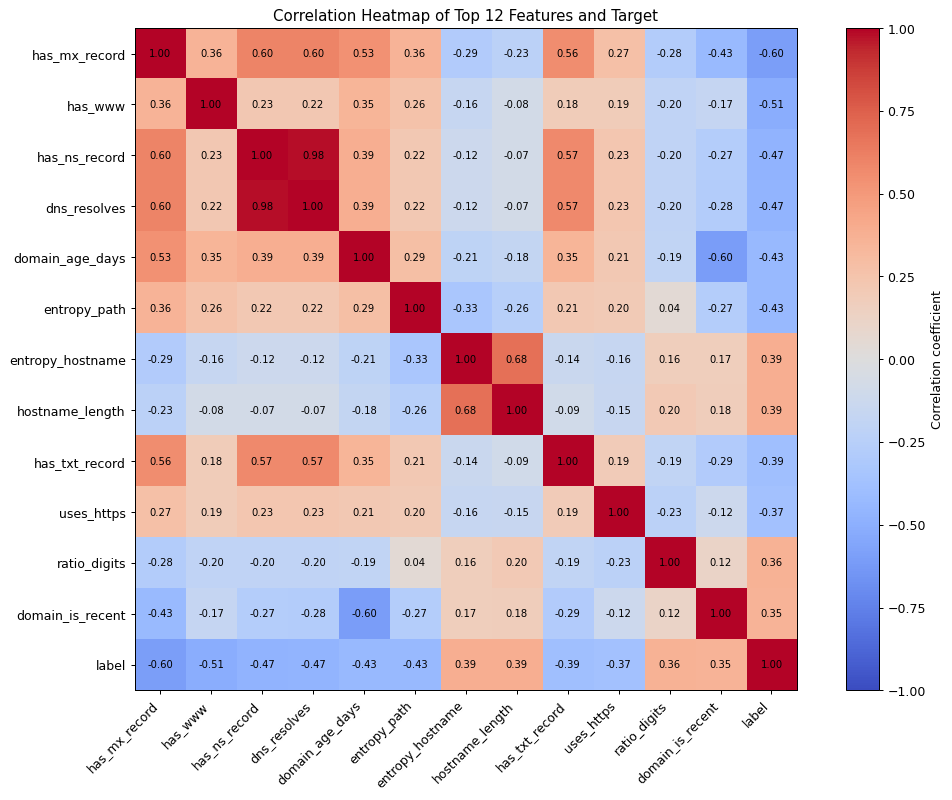

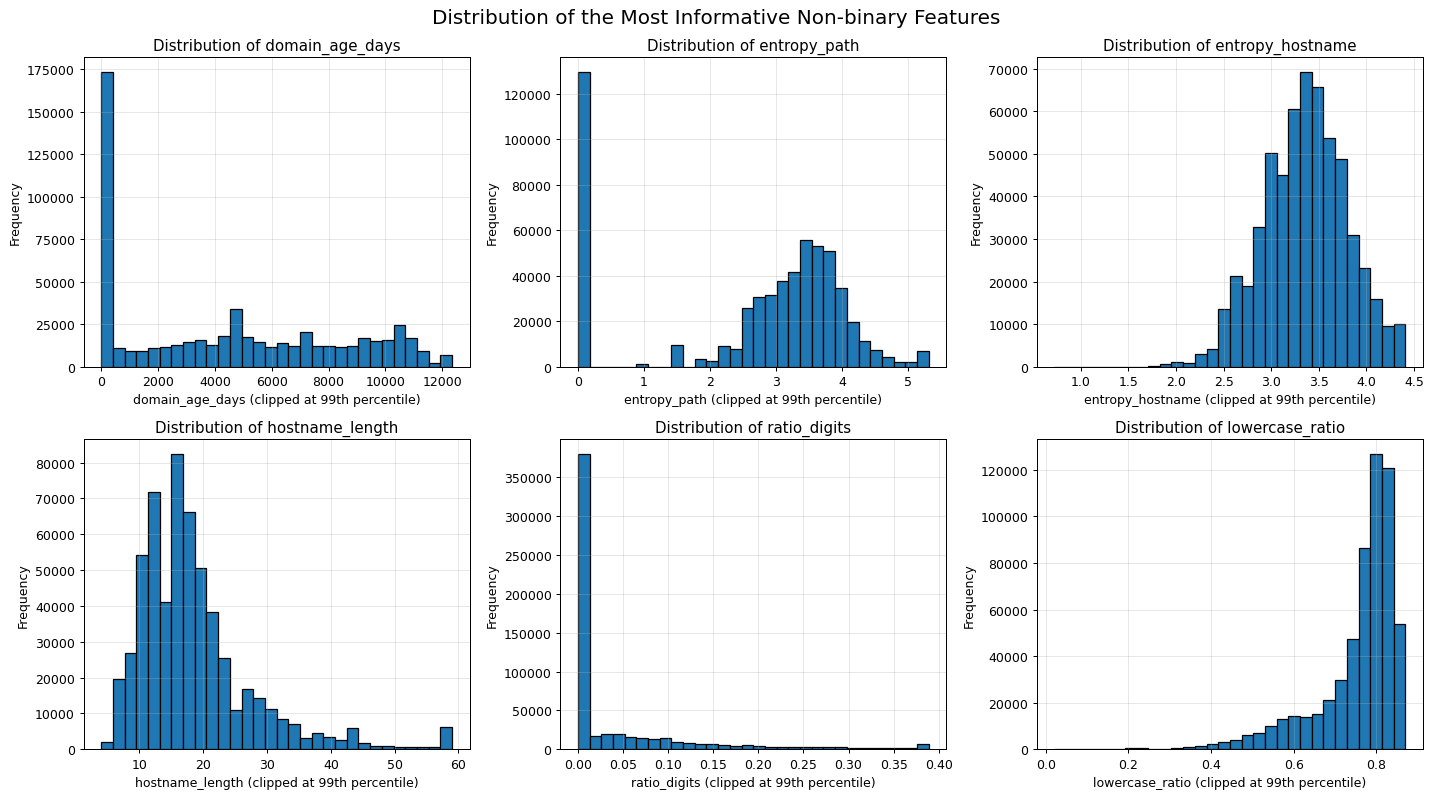

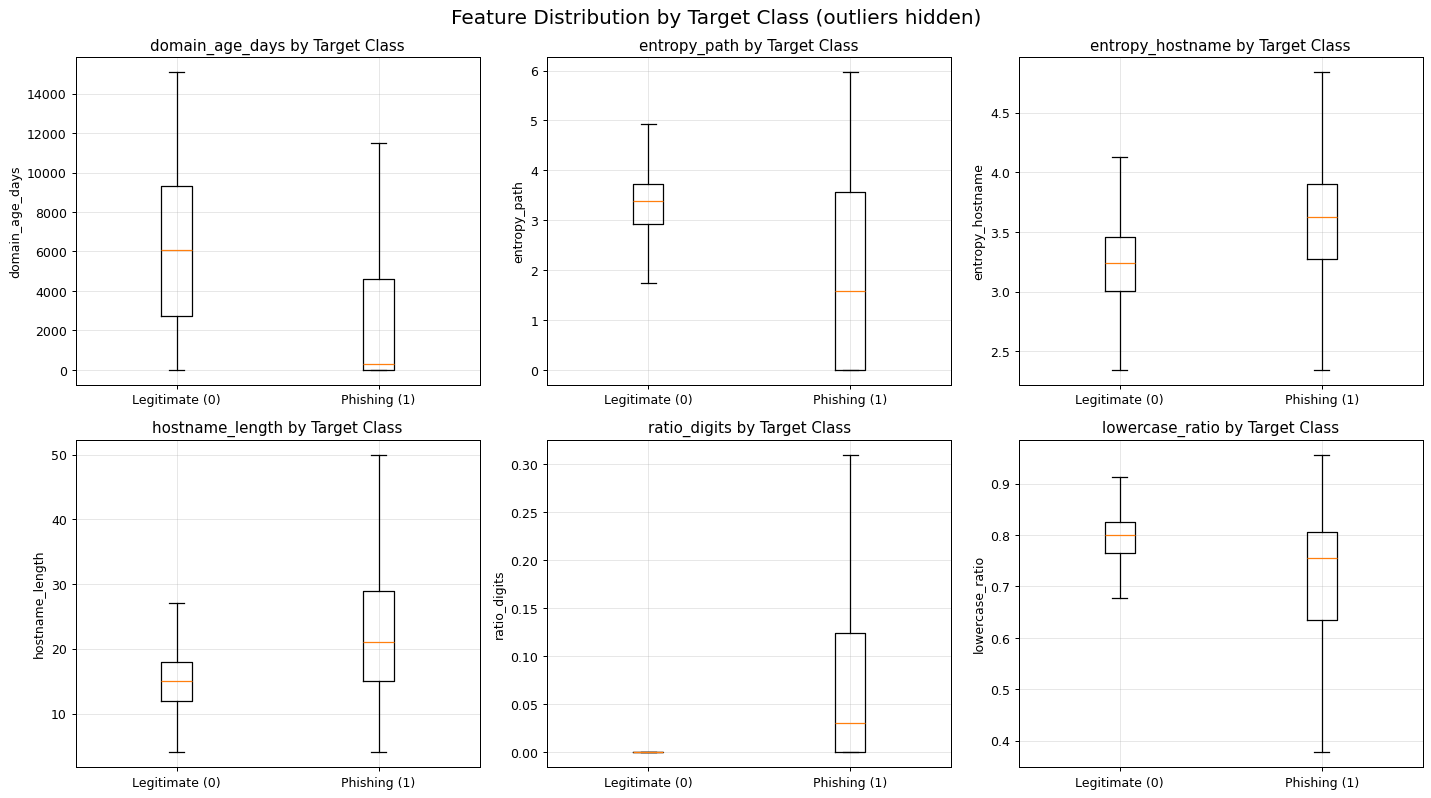

In [6]:
print("=" * 70)
print("EXPLORATORY DATA ANALYSIS (EDA)")
print("=" * 70)

target = "label"
label_names = ["Legitimate (0)", "Phishing (1)"]

# ------------------------------------------------------------
# 1. Відбір найбільш інформативних ознак
# ------------------------------------------------------------
numeric_features = df.drop(columns=[target]).select_dtypes(include="number").columns.tolist()
print(f"Number of numerical features: {len(numeric_features)}")

correlations = df[numeric_features + [target]].corr()[target].drop(target)
sorted_features = correlations.abs().sort_values(ascending=False).index.tolist()

top_features = sorted_features[:12]
print("\nTop 12 features by absolute correlation with target:")
for feature in top_features:
    print(f"{feature:25s} correlation = {correlations[feature]:+.4f}")

# Неординальні (не 0/1) ознаки для гістограм і boxplot
non_binary = [f for f in sorted_features if df[f].nunique() > 2]
plot_features = non_binary[:6]
print("\nNon-binary features used for histograms / boxplots:", plot_features)

# ------------------------------------------------------------
# 2. Heatmap кореляцій
# ------------------------------------------------------------
heatmap_features = top_features + [target]
corr_matrix = df[heatmap_features].corr()

fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(heatmap_features)))
ax.set_yticks(range(len(heatmap_features)))
ax.set_xticklabels(heatmap_features, rotation=45, ha="right")
ax.set_yticklabels(heatmap_features)

for i in range(len(heatmap_features)):
    for j in range(len(heatmap_features)):
        ax.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)

fig.colorbar(im, ax=ax, label="Correlation coefficient")
ax.set_title("Correlation Heatmap of Top 12 Features and Target")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. Гістограми (обрізаємо хвіст на 99-му перцентилі для читабельності)
# ------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, feature in zip(axes, plot_features):
    upper = df[feature].quantile(0.99)
    clipped = df[feature].clip(upper=upper)
    ax.hist(clipped, bins=30, edgecolor="black")
    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(f"{feature} (clipped at 99th percentile)")
    ax.set_ylabel("Frequency")
    ax.grid(alpha=0.3)

plt.suptitle("Distribution of the Most Informative Non-binary Features", fontsize=16)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. Boxplot ознак відносно цільової змінної
# ------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, feature in zip(axes, plot_features):
    data = [df.loc[df[target] == 0, feature], df.loc[df[target] == 1, feature]]
    ax.boxplot(data, showfliers=False)          # без викидів, щоб було видно "ящики"
    ax.set_xticks([1, 2])
    ax.set_xticklabels(label_names)
    ax.set_title(f"{feature} by Target Class")
    ax.set_ylabel(feature)
    ax.grid(alpha=0.3)

plt.suptitle("Feature Distribution by Target Class (outliers hidden)", fontsize=16)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. Короткі статистики
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("EDA SUMMARY: mean / median of selected features by class")
print("=" * 70)
print(df.groupby(target)[plot_features].mean().T.round(3).rename(columns={0: "mean_0", 1: "mean_1"}))
print()
print(df.groupby(target)[plot_features].median().T.round(3).rename(columns={0: "median_0", 1: "median_1"}))

**Коментарі до візуалізацій**

- **Heatmap.** Найсильніше з цільовою змінною корелюють DNS/WHOIS-ознаки: `has_mx_record` (−0,60), `has_www` (−0,51), `has_ns_record` (−0,47), `dns_resolves` (−0,47), `domain_age_days` (−0,43). У легітимних сайтів MX-запис є у 88 % випадків, у фішингових - лише у 30 %; `www` є у 56 % проти 6 %. Серед лексичних ознак найкорисніші `entropy_path` (−0,43), `hostname_length` (+0,39), `entropy_hostname` (+0,39), `ratio_digits` (+0,36). Ознаки всередині груп сильно корелюють між собою (`has_ns_record` ↔ `dns_resolves` ≈ 0,98, `hostname_length` ↔ `entropy_hostname` ≈ 0,68, `domain_age_days` ↔ `domain_is_recent` ≈ −0,60), тобто частина інформації надлишкова - це важливо для лінійних моделей, але дерева до цього стійкі.
- **Гістограми.** Розподіли переважно сильно скошені праворуч (довгі хвости `domain_age_days`, `hostname_length`, тому хвіст обрізано на 99-му перцентилі). У `entropy_path` та `ratio_digits` є великий пік у нулі: багато URL взагалі не мають шляху чи цифр.
- **Boxplot.** Фішингові сайти мають значно молодші домени (медіана 286 днів проти 6077), довші імена хостів (медіана 21 проти 15 символів) та більшу частку цифр (медіана 0,03 проти 0). Для `entropy_path` медіана у фішингових нижча (1,6 проти 3,4), бо у 48 % фішингових URL шлях порожній (проти 4 % у легітимних). Це підтверджує, що ознаки розділяють класи, хоча діапазони частково перетинаються - тому потрібна нелінійна модель, а не одна порогова ознака.

## 4) Підготовка даних до навчання
Розділити дані на training та test вибірки; виконати масштабування/нормалізацію ознак для алгоритмів, для яких це необхідно.

In [7]:
target = "label"

X = df.drop(columns=[target])
y = df[target]

# Розділення на training та test вибірки (стратифіковано за класами)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Розмір training вибірки:", X_train.shape)
print("Розмір test вибірки:", X_test.shape)

print("\nРозподіл класів у training:")
print(y_train.value_counts(normalize=True).round(4))

print("\nРозподіл класів у test:")
print(y_test.value_counts(normalize=True).round(4))

# Масштабування потрібне лише для kNN та SVM (працюють з відстанями / ядрами).
# Дерева, Random Forest та AdaBoost до масштабу ознак нечутливі.
scaler = StandardScaler()
# float32 вдвічі зменшує споживання пам'яті (для kNN/SVM цієї точності більш ніж достатньо)
X_train_scaled = scaler.fit_transform(X_train).astype(np.float32)   # scaler навчається ТІЛЬКИ на training
X_test_scaled = scaler.transform(X_test).astype(np.float32)

# Звільняємо пам'ять: повні копії X, y далі не потрібні
del X, y

print("\nРозмір X_train_scaled:", X_train_scaled.shape)
print("Розмір X_test_scaled:", X_test_scaled.shape)
print("Середнє / std масштабованих training-ознак:",
      round(float(X_train_scaled.mean()), 6), "/", round(float(X_train_scaled.std()), 4))

Розмір training вибірки: (463936, 69)
Розмір test вибірки: (115984, 69)

Розподіл класів у training:
label
0    0.5847
1    0.4153
Name: proportion, dtype: float64

Розподіл класів у test:
label
0    0.5847
1    0.4153
Name: proportion, dtype: float64

Розмір X_train_scaled: (463936, 69)
Розмір X_test_scaled: (115984, 69)
Середнє / std масштабованих training-ознак: -0.0 / 1.0


### Підвибірки для «повільних» алгоритмів
kNN та SVM мають складність приблизно O(n²) за кількістю об'єктів, тому на повному training-наборі (≈464 тис. рядків) вони працювали б занадто довго. Тому:

- **пошук гіперпараметрів** (завдання 6) виконуємо на стратифікованій підвибірці `TUNE_SIZE = 20 000`;
- **kNN та SVM навчаємо** на стратифікованій підвибірці `TRAIN_SUB_SIZE = 100 000`;
- **Decision Tree, Random Forest, AdaBoost** навчаємо на повному training-наборі;
- **оцінюємо всі моделі на одному й тому ж повному test-наборі** (≈116 тис. рядків).

Щоб порівняння було чесним, у п. 7.4 додатково перевіряємо дерева й на тій самій підвибірці 100 000.

In [8]:
TUNE_SIZE = 20_000
TRAIN_SUB_SIZE = 100_000

# Стратифіковані підвибірки лише з training-частини (test не чіпаємо)
X_sub, _, y_sub, _ = train_test_split(
    X_train, y_train, train_size=TRAIN_SUB_SIZE, stratify=y_train, random_state=RANDOM_STATE
)
X_tune, _, y_tune, _ = train_test_split(
    X_train, y_train, train_size=TUNE_SIZE, stratify=y_train, random_state=RANDOM_STATE
)
X_sub_scaled = scaler.transform(X_sub).astype(np.float32)

print("Full training :", X_train.shape)
print("Train subset  :", X_sub.shape, "| phishing share:", round(y_sub.mean(), 4))
print("Tuning subset :", X_tune.shape, "| phishing share:", round(y_tune.mean(), 4))

Full training : (463936, 69)
Train subset  : (100000, 69) | phishing share: 0.4153
Tuning subset : (20000, 69) | phishing share: 0.4153


## 5) Навчання моделей
Навчаємо п'ять класифікаторів зі стандартними (або типовими) гіперпараметрами - це **baseline**, з яким далі порівнюємо налаштовані моделі.

In [9]:
CLASS_NAMES = ["Legitimate (0)", "Phishing (1)"]

def evaluate(name, model, X_te, y_te, fit_time):
    """Прогноз на test + метрики. Повертає словник з результатами."""
    t0 = time.time()
    if hasattr(model, "predict_proba"):
        score = model.predict_proba(X_te)[:, 1]
        y_pred = (score > 0.5).astype(int)
    else:                                   # SVC без probability=True
        score = model.decision_function(X_te)
        y_pred = (score > 0).astype(int)
    predict_time = time.time() - t0

    return {
        "name": name,
        "Accuracy": accuracy_score(y_te, y_pred),
        "Precision": precision_score(y_te, y_pred),
        "Recall": recall_score(y_te, y_pred),
        "F1": f1_score(y_te, y_pred),
        "ROC-AUC": roc_auc_score(y_te, score),
        "Fit, s": fit_time,
        "Predict, s": predict_time,
        "y_pred": y_pred,
        "score": score,
    }

def fit_and_evaluate(name, model, X_tr, y_tr, X_te, y_te):
    t0 = time.time()
    model.fit(X_tr, y_tr)
    fit_time = time.time() - t0
    res = evaluate(name, model, X_te, y_te, fit_time)
    print(f"{name:15s} acc={res['Accuracy']:.4f}  F1={res['F1']:.4f}  "
          f"fit={res['Fit, s']:.1f}s  predict={res['Predict, s']:.1f}s")
    return model, res

baseline_models, baseline_results = {}, {}

# kNN та SVM: масштабовані дані, підвибірка 100 000
baseline_models["kNN"], baseline_results["kNN"] = fit_and_evaluate(
    "kNN", KNeighborsClassifier(n_neighbors=5),
    X_sub_scaled, y_sub, X_test_scaled, y_test)

baseline_models["SVM"], baseline_results["SVM"] = fit_and_evaluate(
    "SVM", SVC(kernel="rbf", C=1.0, gamma="scale"),
    X_sub_scaled, y_sub, X_test_scaled, y_test)

# Дерева та ансамблі: вихідні (немасштабовані) дані, повний training
baseline_models["Decision Tree"], baseline_results["Decision Tree"] = fit_and_evaluate(
    "Decision Tree", DecisionTreeClassifier(random_state=RANDOM_STATE),
    X_train, y_train, X_test, y_test)

baseline_models["Random Forest"], baseline_results["Random Forest"] = fit_and_evaluate(
    "Random Forest", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    X_train, y_train, X_test, y_test)

baseline_models["AdaBoost"], baseline_results["AdaBoost"] = fit_and_evaluate(
    "AdaBoost", AdaBoostClassifier(n_estimators=50, random_state=RANDOM_STATE),
    X_train, y_train, X_test, y_test)

kNN             acc=0.9615  F1=0.9530  fit=0.0s  predict=63.3s
SVM             acc=0.9671  F1=0.9601  fit=109.5s  predict=105.8s
Decision Tree   acc=0.9751  F1=0.9700  fit=16.2s  predict=0.1s
Random Forest   acc=0.9850  F1=0.9817  fit=116.4s  predict=2.5s
AdaBoost        acc=0.9398  F1=0.9265  fit=44.6s  predict=1.0s


## 6) Підбір гіперпараметрів
Гіперпараметри підбираємо **лише за крос-валідацією на training-даних** (підвибірка `X_tune`); test-вибірка на цьому етапі не використовується, щоб не було витоку інформації. Масштабування включаємо в `Pipeline`, щоб `StandardScaler` навчався лише на train-частині кожного фолда.

### 6.1 kNN: підбір `n_neighbors` (та способу зважування)

kNN grid search time: 68.4 s
Best params: {'knn__n_neighbors': 3, 'knn__weights': 'distance'}
Best CV accuracy: 0.9469
 param_knn__n_neighbors param_knn__weights  mean_test_score  std_test_score
                      3           distance          0.94695        0.003367
                      5           distance          0.94660        0.001921
                      7           distance          0.94545        0.001355
                      3            uniform          0.94515        0.003621
                     11           distance          0.94425        0.002297


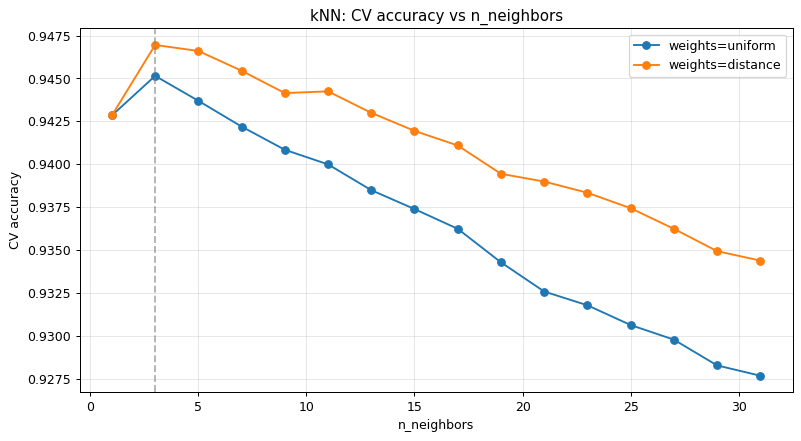

In [10]:
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

knn_pipe = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier())])
knn_grid = {
    "knn__n_neighbors": list(range(1, 32, 2)),      # непарні k від 1 до 31
    "knn__weights": ["uniform", "distance"],
}

t0 = time.time()
knn_search = GridSearchCV(knn_pipe, knn_grid, cv=cv5, scoring="accuracy", n_jobs=-1)
knn_search.fit(X_tune, y_tune)
print(f"kNN grid search time: {time.time() - t0:.1f} s")

print("Best params:", knn_search.best_params_)
print(f"Best CV accuracy: {knn_search.best_score_:.4f}")

# Графік залежності CV-accuracy від k
res = pd.DataFrame(knn_search.cv_results_)
fig, ax = plt.subplots(figsize=(9, 5))
for w in ["uniform", "distance"]:
    part = res[res["param_knn__weights"] == w]
    ax.plot(part["param_knn__n_neighbors"], part["mean_test_score"], marker="o", label=f"weights={w}")
ax.axvline(knn_search.best_params_["knn__n_neighbors"], color="gray", ls="--", alpha=0.6)
ax.set_xlabel("n_neighbors")
ax.set_ylabel("CV accuracy")
ax.set_title("kNN: CV accuracy vs n_neighbors")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

print(res.sort_values("rank_test_score")[["param_knn__n_neighbors", "param_knn__weights",
                                          "mean_test_score", "std_test_score"]].head(5).to_string(index=False))

### 6.2 SVM: підбір `C` та `gamma` за допомогою GridSearchCV

SVM grid search time: 280.4 s
Best params: {'svc__C': 100, 'svc__gamma': 0.005}
Best CV accuracy: 0.9616


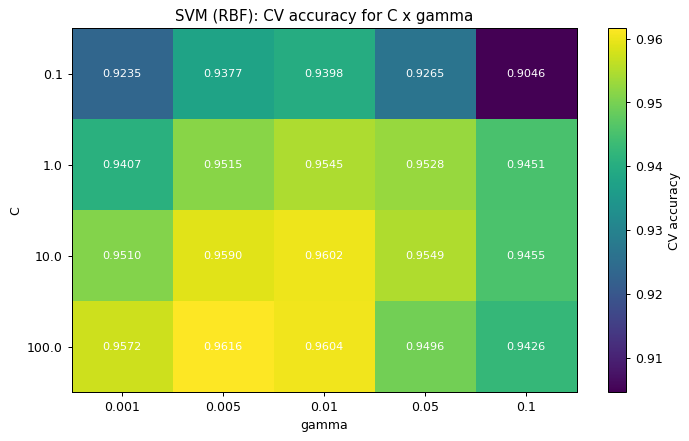

In [11]:
svm_pipe = Pipeline([("scaler", StandardScaler()), ("svc", SVC(kernel="rbf"))])
svm_grid = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": [0.001, 0.005, 0.01, 0.05, 0.1],
}

t0 = time.time()
svm_search = GridSearchCV(svm_pipe, svm_grid, cv=cv3, scoring="accuracy", n_jobs=-1)
svm_search.fit(X_tune, y_tune)
print(f"SVM grid search time: {time.time() - t0:.1f} s")

print("Best params:", svm_search.best_params_)
print(f"Best CV accuracy: {svm_search.best_score_:.4f}")

# Heatmap CV-accuracy за сіткою (C x gamma)
res = pd.DataFrame(svm_search.cv_results_)
table = res.pivot(index="param_svc__C", columns="param_svc__gamma", values="mean_test_score")

fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(table.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(table.shape[1])); ax.set_xticklabels(table.columns)
ax.set_yticks(range(table.shape[0])); ax.set_yticklabels(table.index)
ax.set_xlabel("gamma"); ax.set_ylabel("C")
ax.set_title("SVM (RBF): CV accuracy for C x gamma")
for i in range(table.shape[0]):
    for j in range(table.shape[1]):
        ax.text(j, i, f"{table.values[i, j]:.4f}", ha="center", va="center", color="white", fontsize=9)
fig.colorbar(im, ax=ax, label="CV accuracy")
plt.tight_layout()
plt.show()

### 6.3 (додатково) Decision Tree: `max_depth` та `min_samples_leaf`
Некерований Decision Tree схильний до перенавчання, тому досліджуємо вплив глибини та мінімального розміру листка.

Decision Tree grid search time: 55.8 s
Best params: {'max_depth': 15, 'min_samples_leaf': 1}
Best CV accuracy: 0.9588


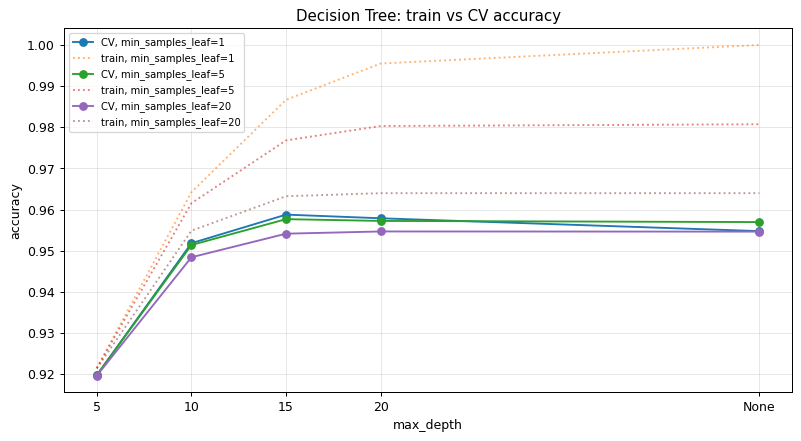

In [12]:
dt_grid = {
    "max_depth": [5, 10, 15, 20, None],
    "min_samples_leaf": [1, 5, 20],
}

t0 = time.time()
dt_search = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), dt_grid,
                         cv=cv3, scoring="accuracy", n_jobs=-1, return_train_score=True)
dt_search.fit(X_sub, y_sub)
print(f"Decision Tree grid search time: {time.time() - t0:.1f} s")
print("Best params:", dt_search.best_params_)
print(f"Best CV accuracy: {dt_search.best_score_:.4f}")

res = pd.DataFrame(dt_search.cv_results_)
res["depth"] = res["param_max_depth"].apply(lambda v: 40 if v is None else v)

fig, ax = plt.subplots(figsize=(9, 5))
for leaf in dt_grid["min_samples_leaf"]:
    part = res[res["param_min_samples_leaf"] == leaf].sort_values("depth")
    ax.plot(part["depth"], part["mean_test_score"], marker="o", label=f"CV, min_samples_leaf={leaf}")
    ax.plot(part["depth"], part["mean_train_score"], ls=":", alpha=0.6, label=f"train, min_samples_leaf={leaf}")
ax.set_xticks([5, 10, 15, 20, 40]); ax.set_xticklabels(["5", "10", "15", "20", "None"])
ax.set_xlabel("max_depth"); ax.set_ylabel("accuracy")
ax.set_title("Decision Tree: train vs CV accuracy")
ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 6.4 (додатково) AdaBoost: `n_estimators` та `learning_rate`

In [13]:
ada_grid = {
    "n_estimators": [50, 100, 200],
    "learning_rate": [0.5, 1.0],
}

t0 = time.time()
ada_search = GridSearchCV(AdaBoostClassifier(random_state=RANDOM_STATE), ada_grid,
                          cv=cv3, scoring="accuracy", n_jobs=-1)
ada_search.fit(X_tune, y_tune)
print(f"AdaBoost grid search time: {time.time() - t0:.1f} s")
print("Best params:", ada_search.best_params_)
print(f"Best CV accuracy: {ada_search.best_score_:.4f}")
print(pd.DataFrame(ada_search.cv_results_)[["param_n_estimators", "param_learning_rate", "mean_test_score"]]
      .sort_values("mean_test_score", ascending=False).to_string(index=False))

AdaBoost grid search time: 57.0 s
Best params: {'learning_rate': 1.0, 'n_estimators': 200}
Best CV accuracy: 0.9486
 param_n_estimators  param_learning_rate  mean_test_score
                200                  1.0          0.94860
                200                  0.5          0.94490
                100                  1.0          0.94320
                 50                  1.0          0.93475
                100                  0.5          0.93210
                 50                  0.5          0.92500


### 6.5 Навчання моделей із найкращими гіперпараметрами
Random Forest залишаємо зі стандартними параметрами (100 дерев): він вже стійкий до вибору гіперпараметрів, тому окремий підбір не проводили.

In [14]:
best_knn = knn_search.best_params_
best_svm = svm_search.best_params_
best_dt = dt_search.best_params_
best_ada = ada_search.best_params_

tuned_models, tuned_results = {}, {}

tuned_models["kNN"], tuned_results["kNN"] = fit_and_evaluate(
    "kNN", KNeighborsClassifier(n_neighbors=best_knn["knn__n_neighbors"], weights=best_knn["knn__weights"]),
    X_sub_scaled, y_sub, X_test_scaled, y_test)

tuned_models["SVM"], tuned_results["SVM"] = fit_and_evaluate(
    "SVM", SVC(kernel="rbf", C=best_svm["svc__C"], gamma=best_svm["svc__gamma"]),
    X_sub_scaled, y_sub, X_test_scaled, y_test)

tuned_models["Decision Tree"], tuned_results["Decision Tree"] = fit_and_evaluate(
    "Decision Tree", DecisionTreeClassifier(random_state=RANDOM_STATE, **best_dt),
    X_train, y_train, X_test, y_test)

tuned_models["Random Forest"], tuned_results["Random Forest"] = (
    baseline_models["Random Forest"], baseline_results["Random Forest"])
print("Random Forest   (default parameters, reused from baseline)")

tuned_models["AdaBoost"], tuned_results["AdaBoost"] = fit_and_evaluate(
    "AdaBoost", AdaBoostClassifier(random_state=RANDOM_STATE, **best_ada),
    X_train, y_train, X_test, y_test)

# Baseline vs tuned
cmp = pd.DataFrame({
    "Baseline acc": {k: v["Accuracy"] for k, v in baseline_results.items()},
    "Tuned acc": {k: v["Accuracy"] for k, v in tuned_results.items()},
    "Baseline F1": {k: v["F1"] for k, v in baseline_results.items()},
    "Tuned F1": {k: v["F1"] for k, v in tuned_results.items()},
})
cmp["Δ acc"] = cmp["Tuned acc"] - cmp["Baseline acc"]
print("\nBaseline vs tuned (test set):")
print(cmp.round(4))

kNN             acc=0.9650  F1=0.9573  fit=0.0s  predict=62.0s
SVM             acc=0.9722  F1=0.9663  fit=215.5s  predict=72.3s
Decision Tree   acc=0.9715  F1=0.9652  fit=9.8s  predict=0.1s
Random Forest   (default parameters, reused from baseline)
AdaBoost        acc=0.9522  F1=0.9419  fit=177.1s  predict=2.1s

Baseline vs tuned (test set):
               Baseline acc  Tuned acc  Baseline F1  Tuned F1   Δ acc
kNN                  0.9615     0.9650       0.9530    0.9573  0.0035
SVM                  0.9671     0.9722       0.9601    0.9663  0.0051
Decision Tree        0.9751     0.9715       0.9700    0.9652 -0.0036
Random Forest        0.9850     0.9850       0.9817    0.9817  0.0000
AdaBoost             0.9398     0.9522       0.9265    0.9419  0.0124


## 7) Порівняння та оцінювання моделей

### 7.1 Зведена таблиця метрик (налаштовані моделі, test-вибірка)
Клас «Phishing» (1) вважаємо позитивним: **Recall** - частка виявлених фішингових сайтів, **Precision** - частка справді фішингових серед тих, що модель позначила фішинговими.

               Accuracy  Precision  Recall      F1  ROC-AUC    Fit, s  Predict, s
Random Forest    0.9850     0.9906  0.9731  0.9817   0.9981  116.4014      2.5466
SVM              0.9722     0.9744  0.9583  0.9663   0.9948  215.4537     72.3030
Decision Tree    0.9715     0.9778  0.9530  0.9652   0.9813    9.8166      0.0780
kNN              0.9650     0.9705  0.9446  0.9573   0.9809    0.0276     61.9681
AdaBoost         0.9522     0.9500  0.9340  0.9419   0.9892  177.0906      2.1255

Best model by F1: Random Forest


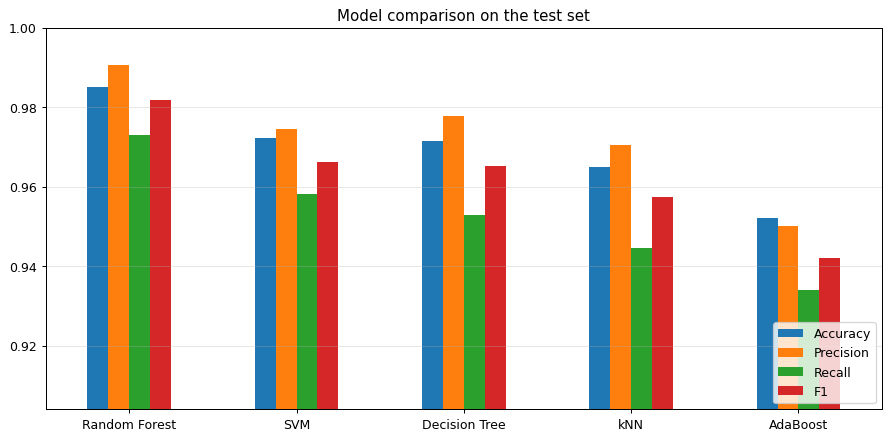

In [15]:
metric_cols = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC", "Fit, s", "Predict, s"]
summary = pd.DataFrame(tuned_results).T[metric_cols].astype(float)
summary = summary.sort_values("F1", ascending=False)
print(summary.round(4).to_string())

best_name = summary.index[0]
print(f"\nBest model by F1: {best_name}")

fig, ax = plt.subplots(figsize=(10, 5))
summary[["Accuracy", "Precision", "Recall", "F1"]].plot.bar(ax=ax, rot=0)
lo = summary[["Accuracy", "Precision", "Recall", "F1"]].min().min()
ax.set_ylim(max(0, lo - 0.03), 1.0)
ax.set_title("Model comparison on the test set")
ax.grid(axis="y", alpha=0.3)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 7.2 classification_report для кожної моделі

In [16]:
for name in summary.index:
    print("=" * 70)
    print(name)
    print("=" * 70)
    print(classification_report(y_test, tuned_results[name]["y_pred"],
                                target_names=CLASS_NAMES, digits=4))

Random Forest
                precision    recall  f1-score   support

Legitimate (0)     0.9811    0.9934    0.9872     67815
  Phishing (1)     0.9906    0.9731    0.9817     48169

      accuracy                         0.9850    115984
     macro avg     0.9858    0.9832    0.9845    115984
  weighted avg     0.9850    0.9850    0.9850    115984

SVM
                precision    recall  f1-score   support

Legitimate (0)     0.9707    0.9821    0.9764     67815
  Phishing (1)     0.9744    0.9583    0.9663     48169

      accuracy                         0.9722    115984
     macro avg     0.9726    0.9702    0.9713    115984
  weighted avg     0.9722    0.9722    0.9722    115984

Decision Tree
                precision    recall  f1-score   support

Legitimate (0)     0.9672    0.9846    0.9758     67815
  Phishing (1)     0.9778    0.9530    0.9652     48169

      accuracy                         0.9715    115984
     macro avg     0.9725    0.9688    0.9705    115984
  weight

### 7.3 confusion_matrix для кожної моделі

Random Forest  TN= 67369  FP=  446  FN= 1297  TP= 46872 | FP-rate (legit flagged as phishing) = 0.0066 | FN-rate (phishing missed) = 0.0269
SVM            TN= 66603  FP= 1212  FN= 2011  TP= 46158 | FP-rate (legit flagged as phishing) = 0.0179 | FN-rate (phishing missed) = 0.0417
Decision Tree  TN= 66772  FP= 1043  FN= 2266  TP= 45903 | FP-rate (legit flagged as phishing) = 0.0154 | FN-rate (phishing missed) = 0.0470
kNN            TN= 66430  FP= 1385  FN= 2670  TP= 45499 | FP-rate (legit flagged as phishing) = 0.0204 | FN-rate (phishing missed) = 0.0554
AdaBoost       TN= 65448  FP= 2367  FN= 3179  TP= 44990 | FP-rate (legit flagged as phishing) = 0.0349 | FN-rate (phishing missed) = 0.0660


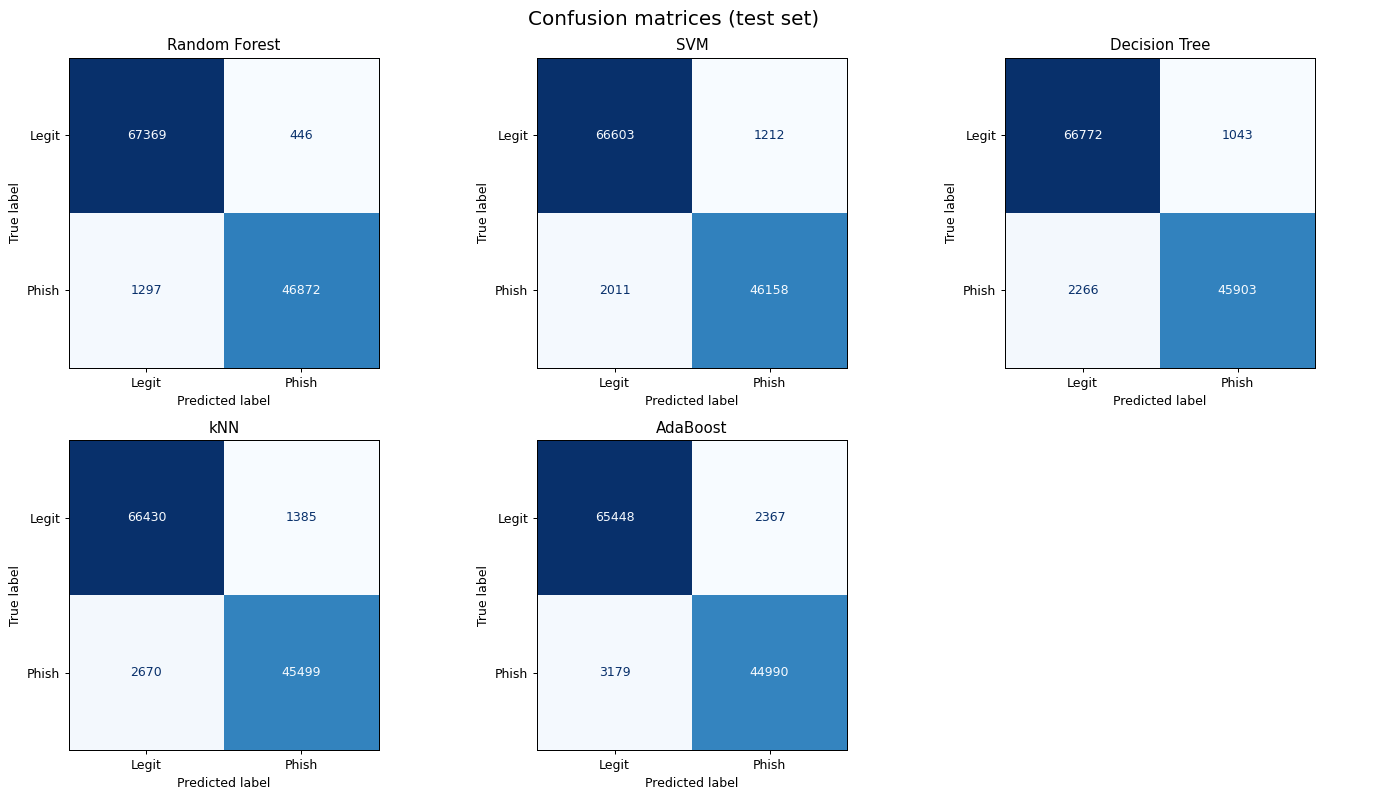

In [17]:
cms = {name: confusion_matrix(y_test, tuned_results[name]["y_pred"]) for name in summary.index}

for name, cm in cms.items():
    tn, fp, fn, tp = cm.ravel()
    print(f"{name:14s} TN={tn:6d}  FP={fp:5d}  FN={fn:5d}  TP={tp:6d} | "
          f"FP-rate (legit flagged as phishing) = {fp / (tn + fp):.4f} | "
          f"FN-rate (phishing missed) = {fn / (fn + tp):.4f}")

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for ax, (name, cm) in zip(axes, cms.items()):
    ConfusionMatrixDisplay(cm, display_labels=["Legit", "Phish"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(name)
axes[-1].axis("off")
plt.suptitle("Confusion matrices (test set)", fontsize=16)
plt.tight_layout()
plt.show()

### 7.4 ROC-криві та перевірка «чесності» порівняння

Tree-based models trained on the SAME 100 000-row subset as kNN / SVM:
Decision Tree   acc=0.9613  F1=0.9529  fit=1.9s  predict=0.1s
Random Forest   acc=0.9767  F1=0.9716  fit=19.6s  predict=1.9s
AdaBoost        acc=0.9519  F1=0.9415  fit=34.0s  predict=3.2s

               Full train acc  100k subset acc
Decision Tree          0.9715           0.9613
Random Forest          0.9850           0.9767
AdaBoost               0.9522           0.9519

kNN (100k): 0.965 | SVM (100k): 0.9722


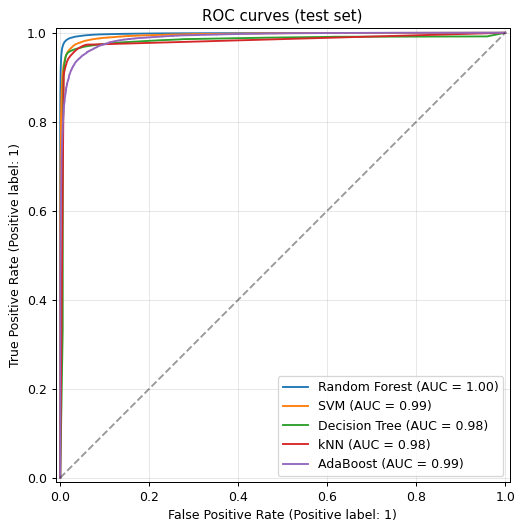

In [18]:
fig, ax = plt.subplots(figsize=(7, 6))
for name in summary.index:
    RocCurveDisplay.from_predictions(y_test, tuned_results[name]["score"], name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
ax.set_title("ROC curves (test set)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Дерева й ансамблі вище навчались на повному training. Перевіряємо, чи не в цьому їхня перевага:
# навчаємо їх на тій самій підвибірці 100 000, що й kNN / SVM.
print("Tree-based models trained on the SAME 100 000-row subset as kNN / SVM:")
same_size = {}
for name, model in {
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE, **best_dt),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    "AdaBoost": AdaBoostClassifier(random_state=RANDOM_STATE, **best_ada),
}.items():
    _, same_size[name] = fit_and_evaluate(name, model, X_sub, y_sub, X_test, y_test)

fair = pd.DataFrame({
    "Full train acc": {k: tuned_results[k]["Accuracy"] for k in same_size},
    "100k subset acc": {k: same_size[k]["Accuracy"] for k in same_size},
})
print()
print(fair.round(4))
print("\nkNN (100k):", round(tuned_results["kNN"]["Accuracy"], 4), "| SVM (100k):", round(tuned_results["SVM"]["Accuracy"], 4))

### 7.5 Важливість ознак (найкраща модель)

has_mx_record       0.0996
entropy_path        0.0804
has_www             0.0596
hostname_length     0.0551
entropy_hostname    0.0514
ttl_value           0.0503
first_dir_length    0.0432
domain_age_days     0.0400
url_depth           0.0380
ip_count            0.0362


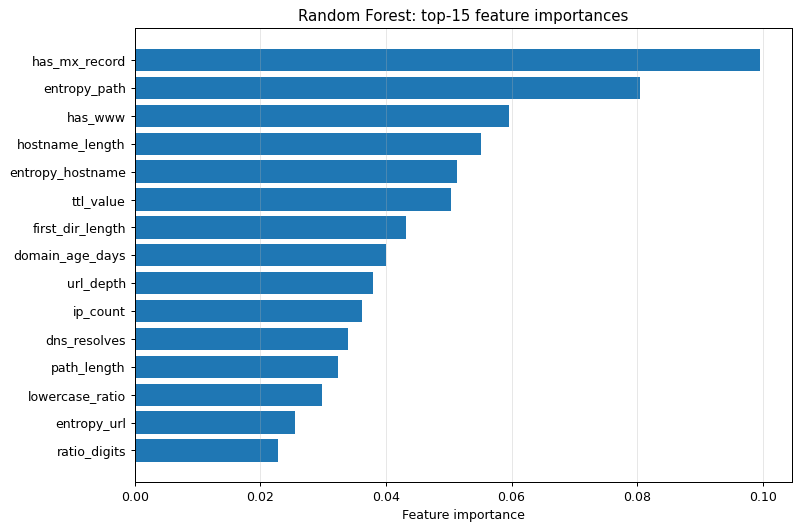

In [19]:
best_model = tuned_models[best_name]
if hasattr(best_model, "feature_importances_"):
    imp = pd.Series(best_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
    print(imp.head(10).round(4).to_string())

    top = imp.head(15)[::-1]
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(top.index, top.values)
    ax.set_xlabel("Feature importance")
    ax.set_title(f"{best_name}: top-15 feature importances")
    ax.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()

### 7.6 Висновок

**Найкраща модель - Random Forest** (без додаткового налаштування): accuracy **0,9850**, F1 для класу «Phishing» **0,9817**, ROC-AUC **0,998**. Вона найкраща і за precision (0,991), і за recall (0,973): із ≈116 тис. тестових URL помилилась лише у 1743 випадках (446 легітимних помічено як фішингові, 1297 фішингових пропущено). Далі за F1: SVM (0,966), Decision Tree (0,965), kNN (0,957), AdaBoost (0,942).

**Чому Random Forest підходить цим даним:**
1. Ознаки різнорідні: бінарні прапорці, лічильники, довжини, частки, ентропії, дні - на різних шкалах і з важкими хвостами. Дерева не потребують масштабування та стійкі до викидів і службових значень (`creation_year` = 0).
2. Залежності нелінійні й мають характер правил на кшталт «немає MX-запису і молодий домен і довгий хост → фішинг» - це природно для дерев.
3. Ансамбль із 100 некорельованих дерев зменшує дисперсію одиночного Decision Tree (F1 0,965 → 0,982) і відносно стійкий до надлишкових, сильно корельованих ознак.
4. Дані багато: на повному training-наборі (≈464 тис.) ліс отримує перевагу, яка недоступна kNN та SVM, що масштабуються погано.

**Додаткові спостереження:**
- **Чесність порівняння.** На однаковій підвибірці 100 000 рядків Random Forest все одно найкращий (accuracy 0,9767 проти 0,9722 у SVM і 0,9650 у kNN), тобто перевага не зводиться лише до більшого обсягу навчальних даних. Але Decision Tree на 100 000 (0,9613) поступається і SVM, і kNN, тож його результат на повному наборі частково завдячує обсягу даних.
- **Вплив налаштування.** Підбір гіперпараметрів допоміг kNN (+0,35 п.п.), SVM (+0,51 п.п.) та особливо AdaBoost (+1,24 п.п.; більше оцінювачів, `n_estimators` = 200). Для Decision Tree налаштування на підвибірці (`max_depth` = 15) навіть трохи погіршило test-результат (−0,36 п.п.): на повних даних глибші дерева виявились кращими, тобто оптимум залежить від обсягу даних. Для SVM найкраще значення `C` = 100 лежить на межі сітки, тож розширення сітки (наприклад, `C` = 300, 1000) могло б дати ще невеликий приріст.
- **Ціна помилки.** У задачі виявлення фішингу дорожча помилка другого роду (пропущений фішинговий сайт). Random Forest має найнижчий рівень пропусків (2,7 %, проти 4,2 % у SVM і 6,6 % у AdaBoost) та найменшу частку хибних тривог (0,7 %). Якщо потрібно ще менше пропусків, поріг класифікації можна знизити (наприклад, до 0,4) ціною зростання хибних спрацювань.
- **Швидкість.** Decision Tree навчається за ≈10 с і майже миттєво прогнозує, але поступається лісу за якістю. SVM і kNN на цих даних повільні за прогнозуванням (≈1 хв на 116 тис. об'єктів) і використовують лише підвибірку.
- **Важливі ознаки.** Найбільший внесок у Random Forest дають `has_mx_record`, `entropy_path`, `has_www`, `hostname_length`, `entropy_hostname`, `ttl_value`, `domain_age_days` - тобто поєднання DNS/WHOIS-ознак і лексики URL.

**Обмеження.** Частина ознак (DNS, WHOIS) збирається запитами до мережі: вони дуже інформативні, але їх треба отримувати в реальному часі, і для щойно створеного або недоступного домену вони можуть бути порожніми (нулі). Крім того, тестова вибірка отримана випадковим розбиттям того самого набору, тому на URL з іншого джерела або періоду якість може бути нижчою. Результати kNN/SVM отримано на підвибірці 100 000, тож із повними даними вони могли б трохи покращитись.